## Baseline Notebook ##

### Project Approach ### 

1. Analyze Planetary Comp SAR Data
2. Collect and Analyze labeled SAR Images
3. Establish a Deterministic Prediction Model
4. Train a basic ML Detection Model
5. Write analysis

In [1]:
# Tile Analysis
import requests
import pandas as pd
import pystac_client
from PIL import Image
from io import BytesIO
import geopandas as gpd
import planetary_computer
import matplotlib.pyplot as plt
from shapely.geometry import shape

# Data Anslysis
import rasterio
import planetary_computer
import numpy as np
import matplotlib.pyplot as plt

from get_city import get_closest_city

This first cell collects several items and displays the basic metadata that each tile contains.

In [ ]:
# Setup Planetary Computer connection
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

search = catalog.search(
    collections=["sentinel-1-rtc"],
    bbox=[-5.8, 35.7, -5.1, 36.3],
    datetime="2025-01-01/2025-12-31",
    max_items=10,
)

# Item Analysis
items = list(search.items())
print(f'Total Tiles Collected{len(items)}\n')

# Tile Analysis
tile = items[0]
print('Each Tile Contains the following Assets:')
for key in tile.assets.keys(): print(key)



Total Tiles Collected10

Each Tile Contains the following Assets:
vh
vv
tilejson
rendered_preview




This next cell does a deep dive into the first tile.

This scene is centered on 36.1235, -4.1607

[{'id': 1796236, 'name': 'Shanghai', 'country': 'CN', 'admin1': 'Shanghai', 'admin2': 'Shanghai Municipality', 'lat': '31.2222200', 'lon': '121.4580600', 'pop': '24874500'}, {'id': 1816670, 'name': 'Beijing', 'country': 'CN', 'admin1': 'Beijing', 'admin2': 'Beijing', 'lat': '39.9075000', 'lon': '116.3972300', 'pop': '18960744'}]
The closest city to this tile is Fuengirola, ES which is 61.82 km from scene center


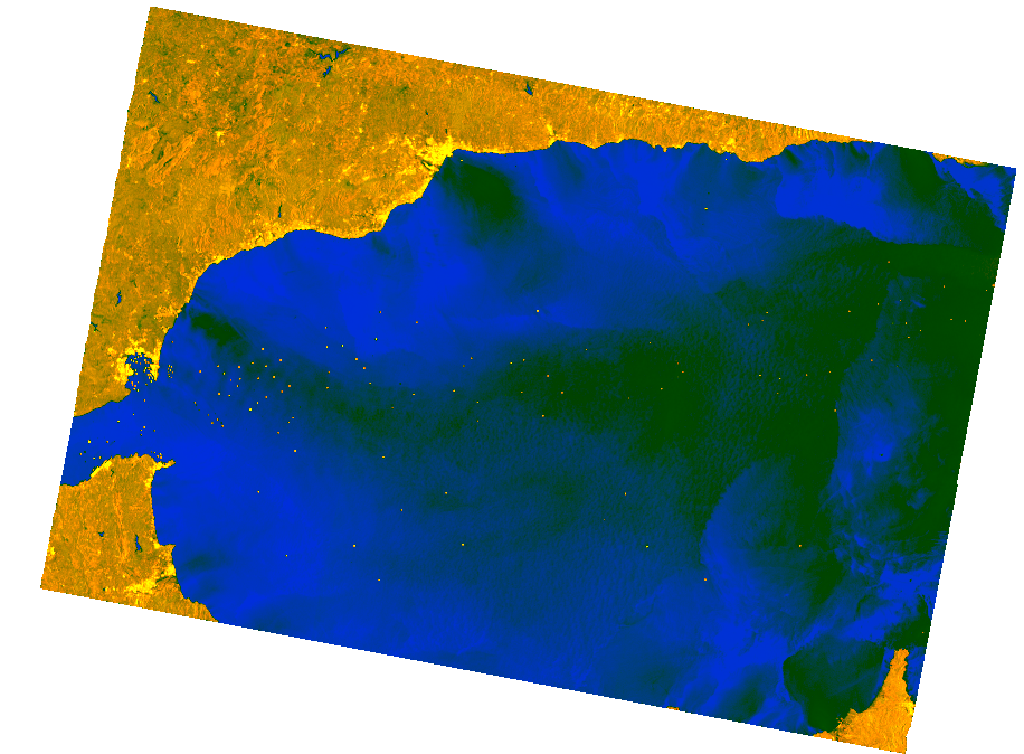

In [13]:
# Geometry Analysis
polygon = shape(tile.geometry)
centroid = polygon.centroid
lon, lat = centroid.x, centroid.y #Centerpoint
print(f'This scene is centered on {lat:.4f}, {lon:.4f}\n')

# Find Nearest City
city, dist = get_closest_city(tile)
print(f"The closest city to this tile is {city['name']}, {city['country']} which is {dist/1000:.2f} km from scene center")

# Fetch image
response = requests.get(tile.assets["rendered_preview"].href)
response.raise_for_status()

# Open image
img = Image.open(BytesIO(response.content))

# Display
img

The next cell goes into basic data analysis of the vv and vh polarizations

In [ ]:
signed = planetary_computer.sign(tile)

with rasterio.open(signed.assets["vv"].href) as src:
    vv = src.read(1)

with rasterio.open(signed.assets["vh"].href) as src:
    vh = src.read(1)

# Convert positive linear backscatter to dB
vv_db = np.where(vv > 0, 10 * np.log10(np.maximum(vv, 1e-10)), np.nan)
vh_db = np.where(vh > 0, 10 * np.log10(np.maximum(vh, 1e-10)), np.nan)